# Streamflow Forecasting with ANN and LSTM
### Xiao & You methodology — compact final experiment

This notebook uses the same **public-data reconstruction** as the previous version:
- USGS Leaf River near Collins, Mississippi daily streamflow
- NOAA Collins daily precipitation
- 2003–2012
- 2003–2007 training / 2008–2012 validation

It implements the two models explicitly used in the paper:
**standard feed-forward ANN and LSTM**.

The final training is improved in two important ways:
1. `EarlyStopping(..., restore_best_weights=True)` selects the model with the **lowest validation loss**, rather than blindly using epoch 200.
2. Training is run with `shuffle=False` because these are time-series observations.

The paper's reported configurations are also retained:
- ANN: rainfall lag 3, runoff lag 4, 12 hidden neurons, learning rate 0.009
- LSTM: lag 5, 12 hidden neurons, learning rate 0.001

> This is a methodology reconstruction using public data, not a claim that the authors' original raw rainfall file was obtained.

In [1]:
# Run once in a fresh Kaggle/Colab environment if needed
!pip -q install pandas numpy matplotlib scikit-learn tensorflow requests joblib seaborn

In [2]:
import os, io, json, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)

START_DATE, END_DATE = "2003-01-01", "2012-12-31"
TRAIN_END, VALID_START = "2007-12-31", "2008-01-01"

USGS_SITE = "02472000"
NOAA_STATION = "USC00221852"

PAPER_MAX_RUNOFF = 29700.0
PAPER_MAX_RAINFALL = 6.8
PEAK_THRESHOLD = 1500.0

PAPER_ANN = dict(rain_lag=3, runoff_lag=4, hidden=12, lr=0.009)
PAPER_LSTM = dict(lag=5, hidden=12, lr=0.001)

SEARCH_EPOCHS = 40
FINAL_EPOCHS = 200
BATCH_SIZE = 32

os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [3]:
# ---------- Download + clean the same public-data reconstruction ----------
# This cell is self-contained: it imports requests here as well, so it
# still works if the notebook kernel was restarted or an earlier cell was skipped.
import requests
import io
import pandas as pd
import numpy as np

def download_usgs(site, start_date, end_date):
    url = (
        "https://waterservices.usgs.gov/nwis/dv/"
        f"?format=rdb&sites={site}&startDT={start_date}&endDT={end_date}"
        "&statCd=00003&parameterCd=00060"
    )
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    lines = [x for x in r.text.splitlines() if x and not x.startswith("#")]
    hi = next(i for i, x in enumerate(lines) if "datetime" in x and "00060" in x)
    header = lines[hi].split("\t")
    rows = [x.split("\t")[:len(header)] for x in lines[hi+2:] if len(x.split("\t")) >= len(header)]
    raw = pd.DataFrame(rows, columns=header)
    value_col = next(c for c in raw.columns if "00060" in c and "00060_" in c)
    out = pd.DataFrame({
        "date": pd.to_datetime(raw["datetime"], errors="coerce"),
        "runoff_cfs": pd.to_numeric(raw[value_col], errors="coerce")
    })
    return out.dropna().drop_duplicates("date").sort_values("date")

def download_noaa(station):
    url = f"https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{station}.csv"
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    raw = pd.read_csv(io.StringIO(r.text))
    raw["DATE"] = pd.to_datetime(raw["DATE"], errors="coerce")
    raw["PRCP"] = pd.to_numeric(raw["PRCP"], errors="coerce")
    out = raw[["DATE", "PRCP"]].rename(columns={"DATE":"date", "PRCP":"rainfall_tenth_mm"})
    out["rainfall_in"] = out["rainfall_tenth_mm"] / 10 / 25.4
    return out[["date","rainfall_in"]].drop_duplicates("date").sort_values("date")

print("Downloading USGS streamflow...")
runoff = download_usgs(USGS_SITE, START_DATE, END_DATE)
print("Downloading NOAA precipitation...")
rain = download_noaa(NOAA_STATION)

df = pd.merge(runoff, rain, on="date", how="inner")
df = df[(df.date >= START_DATE) & (df.date <= END_DATE)].copy()
df["runoff_cfs"] = pd.to_numeric(df["runoff_cfs"], errors="coerce")
df["rainfall_in"] = pd.to_numeric(df["rainfall_in"], errors="coerce")
df.loc[df["runoff_cfs"] < 0, "runoff_cfs"] = np.nan
df.loc[df["rainfall_in"] < 0, "rainfall_in"] = np.nan
df["rainfall_in"] = df["rainfall_in"].interpolate(limit=3, limit_direction="both")
df = df.dropna(subset=["runoff_cfs","rainfall_in"]).sort_values("date").reset_index(drop=True)

df.to_csv("data/leaf_river_2003_2012_public_reconstruction.csv", index=False)

print(f"Rows: {len(df):,}")
print(f"Period: {df.date.min().date()} → {df.date.max().date()}")
print(f"Maximum runoff: {df.runoff_cfs.max():,.1f} ft³/s")
print(f"Maximum rainfall: {df.rainfall_in.max():.2f} in")
display(df[["runoff_cfs","rainfall_in"]].describe().round(3))

Rows: 3,652
Period: 2003-01-01 → 2012-12-31
Maximum runoff: 29,700.0 ft³/s
Maximum rainfall: 6.96 in


,runoff_cfs,rainfall_in
count,3652.000,3652.000
mean,858.238,0.151
std,1859.311,0.489
min,53.300,0.000
25%,135.000,0.000
50%,280.000,0.000
75%,689.250,0.000
max,29700.000,6.961


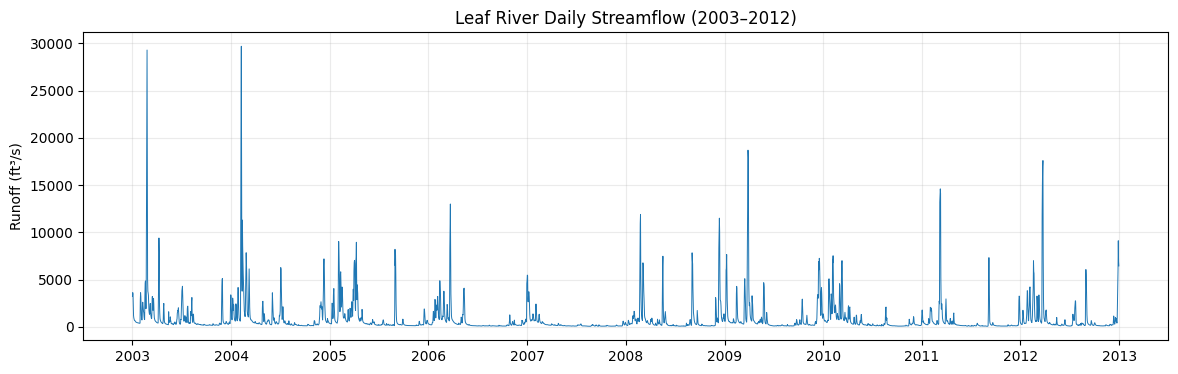

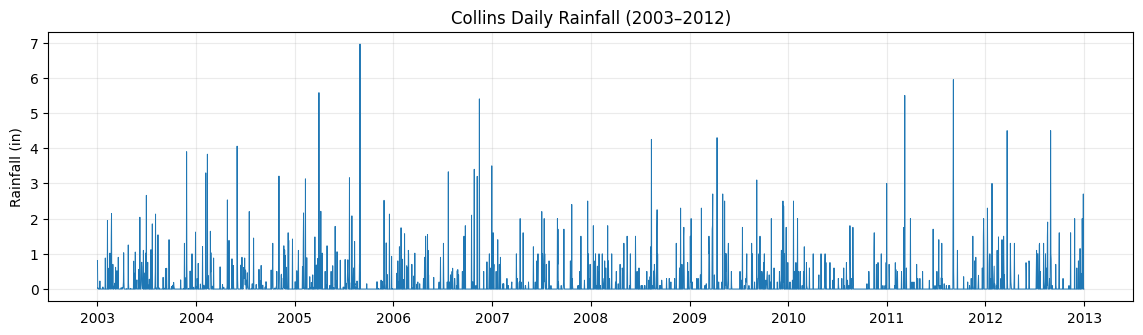

Training rows: 1826
Validation rows: 1826
Peak observations (>1500 ft³/s): 490


In [4]:
# ---------- EDA ----------

fig, ax = plt.subplots(figsize=(14,4))
ax.plot(df.date, df.runoff_cfs, linewidth=0.7)
ax.set_title("Leaf River Daily Streamflow (2003–2012)")
ax.set_ylabel("Runoff (ft³/s)")
ax.grid(alpha=.25)
plt.show()

fig, ax = plt.subplots(figsize=(14,3.5))
ax.plot(df.date, df.rainfall_in, linewidth=0.7)
ax.set_title("Collins Daily Rainfall (2003–2012)")
ax.set_ylabel("Rainfall (in)")
ax.grid(alpha=.25)
plt.show()

print("Training rows:", (df.date <= TRAIN_END).sum())
print("Validation rows:", (df.date >= VALID_START).sum())
print("Peak observations (>1500 ft³/s):", (df.runoff_cfs > PEAK_THRESHOLD).sum())

In [5]:
# ---------- Feature builders, models, evaluation and best-weight training ----------

def lag_table(data, rain_lag, runoff_lag):
    x = data.copy()
    for k in range(1, rain_lag + 1):
        x[f"R{k}"] = x.rainfall_in.shift(k)
    for k in range(1, runoff_lag + 1):
        x[f"Q{k}"] = x.runoff_cfs.shift(k)
    return x.dropna().reset_index(drop=True)

def ann_arrays(x):
    cols = [c for c in x.columns if c.startswith("R") or c.startswith("Q")]
    tr = x[x.date <= TRAIN_END]
    va = x[x.date >= VALID_START]

    Xtr = tr[cols].values.astype("float32")
    Xva = va[cols].values.astype("float32")
    for j, c in enumerate(cols):
        scale = PAPER_MAX_RAINFALL if c.startswith("R") else PAPER_MAX_RUNOFF
        Xtr[:, j] /= scale
        Xva[:, j] /= scale

    ytr = (tr.runoff_cfs.values / PAPER_MAX_RUNOFF).astype("float32")
    yva = (va.runoff_cfs.values / PAPER_MAX_RUNOFF).astype("float32")
    return tr, va, Xtr, ytr, Xva, yva

def make_lstm_arrays(data, lag):
    z = data.copy()
    z["Q"] = z.runoff_cfs / PAPER_MAX_RUNOFF
    z["R"] = z.rainfall_in / PAPER_MAX_RAINFALL

    X, y, raw, dates = [], [], [], []
    for t in range(lag, len(z)):
        X.append(z.loc[t-lag:t-1, ["Q", "R"]].values.astype("float32"))
        y.append(z.loc[t, "Q"])
        raw.append(z.loc[t, "runoff_cfs"])
        dates.append(z.loc[t, "date"])

    X = np.asarray(X); y = np.asarray(y)
    dates = pd.to_datetime(dates)
    train_mask = dates <= TRAIN_END
    valid_mask = dates >= VALID_START
    return X[train_mask], y[train_mask], X[valid_mask], y[valid_mask], np.asarray(raw)[valid_mask], dates[valid_mask]

def build_ann(nin, hidden, lr):
    m = tf.keras.Sequential([
        tf.keras.layers.Input((nin,)),
        tf.keras.layers.Dense(hidden, activation="sigmoid"),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return m

def build_lstm(lag, hidden, lr):
    m = tf.keras.Sequential([
        tf.keras.layers.Input((lag, 2)),
        tf.keras.layers.LSTM(hidden),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return m

def metrics(y_true, pred):
    y_true, pred = np.ravel(y_true), np.ravel(pred)
    peak = y_true > PEAK_THRESHOLD
    non = ~peak
    rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
    return {
        "RMSE_cfs": rmse(y_true, pred),
        "RMSE_%": 100 * rmse(y_true, pred) / PAPER_MAX_RUNOFF,
        "MAE_cfs": mean_absolute_error(y_true, pred),
        "R2": r2_score(y_true, pred),
        "Peak_RMSE_cfs": rmse(y_true[peak], pred[peak]) if peak.any() else np.nan,
        "Peak_RMSE_%": 100 * rmse(y_true[peak], pred[peak]) / PAPER_MAX_RUNOFF if peak.any() else np.nan,
        "NonPeak_RMSE_cfs": rmse(y_true[non], pred[non]) if non.any() else np.nan,
        "NonPeak_RMSE_%": 100 * rmse(y_true[non], pred[non]) / PAPER_MAX_RUNOFF if non.any() else np.nan
    }

def callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=20, mode="min",
            restore_best_weights=True, verbose=0
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=8,
            min_lr=1e-6, mode="min", verbose=0
        )
    ]

def fit_ann(rlag, qlag, hidden=12, lr=0.009, epochs=FINAL_EPOCHS):
    tf.keras.backend.clear_session()
    x = lag_table(df, rlag, qlag)
    tr, va, Xtr, ytr, Xva, yva = ann_arrays(x)
    model = build_ann(Xtr.shape[1], hidden, lr)
    hist = model.fit(
        Xtr, ytr, validation_data=(Xva, yva),
        epochs=epochs, batch_size=BATCH_SIZE,
        shuffle=False, callbacks=callbacks(), verbose=0
    )
    pred = model.predict(Xva, verbose=0).ravel() * PAPER_MAX_RUNOFF
    return model, hist, va, pred, metrics(va.runoff_cfs.values, pred)

def fit_lstm(lag, hidden=12, lr=0.001, epochs=FINAL_EPOCHS):
    tf.keras.backend.clear_session()
    Xtr, ytr, Xva, yva, raw, dates = make_lstm_arrays(df, lag)
    model = build_lstm(lag, hidden, lr)
    hist = model.fit(
        Xtr, ytr, validation_data=(Xva, yva),
        epochs=epochs, batch_size=BATCH_SIZE,
        shuffle=False, callbacks=callbacks(), verbose=0
    )
    pred = model.predict(Xva, verbose=0).ravel() * PAPER_MAX_RUNOFF
    return model, hist, raw, dates, pred, metrics(raw, pred)

In [6]:
# ---------- Compact lag experiment ----------
# We keep hidden neurons fixed at the paper's 12 and vary lag length.
# This demonstrates the paper's lag-search idea without training hundreds of models.

ann_lags = []
for lag in range(2, 8):
    m, h, va, pred, met = fit_ann(lag, lag + 1, hidden=12, lr=0.009, epochs=SEARCH_EPOCHS)
    ann_lags.append({"rain_lag": lag, "runoff_lag": lag + 1, **met})

lstm_lags = []
for lag in range(2, 8):
    m, h, raw, dates, pred, met = fit_lstm(lag, hidden=12, lr=0.001, epochs=SEARCH_EPOCHS)
    lstm_lags.append({"lag": lag, **met})

ann_lags = pd.DataFrame(ann_lags).sort_values("RMSE_cfs").reset_index(drop=True)
lstm_lags = pd.DataFrame(lstm_lags).sort_values("RMSE_cfs").reset_index(drop=True)

ann_lags.to_csv("results/ann_lag_search.csv", index=False)
lstm_lags.to_csv("results/lstm_lag_search.csv", index=False)

print("ANN lag experiment:")
display(ann_lags.round(4))
print("LSTM lag experiment:")
display(lstm_lags.round(4))

ANN lag experiment:


,rain_lag,runoff_lag,RMSE_cfs,RMSE_%,MAE_cfs,R2,Peak_RMSE_cfs,Peak_RMSE_%,NonPeak_RMSE_cfs,NonPeak_RMSE_%
0,6,7,689.3288,2.3210,229.8112,0.8492,1903.6022,6.4094,180.8014,0.6088
1,4,5,701.4207,2.3617,231.8293,0.8438,1944.3725,6.5467,172.6887,0.5814
2,2,3,703.8466,2.3699,224.9462,0.8427,1960.8003,6.6020,157.1421,0.5291
3,7,8,710.3142,2.3916,242.5926,0.8398,1965.6407,6.6183,180.1504,0.6066
4,5,6,725.9776,2.4444,244.8328,0.8327,2015.0383,6.7846,174.5808,0.5878
5,3,4,727.6608,2.4500,240.5603,0.8319,2018.8890,6.7976,176.3125,0.5936


LSTM lag experiment:


,lag,RMSE_cfs,RMSE_%,MAE_cfs,R2,Peak_RMSE_cfs,Peak_RMSE_%,NonPeak_RMSE_cfs,NonPeak_RMSE_%
0,7,699.7821,2.3562,229.9185,0.8445,1944.2382,6.5463,165.1548,0.5561
1,4,703.0754,2.3673,237.4939,0.8431,1948.3394,6.5601,174.0743,0.5861
2,2,712.5527,2.3992,235.8604,0.8388,1986.2026,6.6876,157.0582,0.5288
3,6,714.2939,2.4050,254.7803,0.8380,1963.5071,6.6111,200.2466,0.6742
4,3,743.9930,2.5050,268.8461,0.8243,2066.3854,6.9575,176.7201,0.5950
5,5,753.6665,2.5376,276.1211,0.8197,2069.1108,6.9667,214.8715,0.7235


In [7]:
# ---------- Final models: paper settings + best lag settings ----------

# Paper configurations
ann_p_model, ann_p_hist, ann_p_va, ann_p_pred, ann_p_metrics = fit_ann(
    PAPER_ANN["rain_lag"], PAPER_ANN["runoff_lag"],
    PAPER_ANN["hidden"], PAPER_ANN["lr"], FINAL_EPOCHS
)

lstm_p_model, lstm_p_hist, lstm_p_raw, lstm_p_dates, lstm_p_pred, lstm_p_metrics = fit_lstm(
    PAPER_LSTM["lag"], PAPER_LSTM["hidden"], PAPER_LSTM["lr"], FINAL_EPOCHS
)

# Best lag pairs found by the compact experiment
best_ann_row = ann_lags.iloc[0]
best_lstm_row = lstm_lags.iloc[0]

ann_b_model, ann_b_hist, ann_b_va, ann_b_pred, ann_b_metrics = fit_ann(
    int(best_ann_row["rain_lag"]), int(best_ann_row["runoff_lag"]),
    hidden=12, lr=0.009, epochs=FINAL_EPOCHS
)

lstm_b_model, lstm_b_hist, lstm_b_raw, lstm_b_dates, lstm_b_pred, lstm_b_metrics = fit_lstm(
    int(best_lstm_row["lag"]), hidden=12, lr=0.001, epochs=FINAL_EPOCHS
)

ann_p_model.save("models/paper_config_ann_best.keras")
lstm_p_model.save("models/paper_config_lstm_best.keras")
ann_b_model.save("models/best_lag_ann.keras")
lstm_b_model.save("models/best_lag_lstm.keras")

def best_epoch(hist):
    vals = np.asarray(hist.history["val_loss"])
    i = int(np.argmin(vals))
    return i + 1, float(vals[i])

ann_p_epoch, ann_p_val = best_epoch(ann_p_hist)
lstm_p_epoch, lstm_p_val = best_epoch(lstm_p_hist)
ann_b_epoch, ann_b_val = best_epoch(ann_b_hist)
lstm_b_epoch, lstm_b_val = best_epoch(lstm_b_hist)

comparison = pd.DataFrame([
    {"Model":"ANN - paper config", **ann_p_metrics,
     "Parameters":"rain lag 3, runoff lag 4, hidden 12, lr 0.009",
     "Best epoch":ann_p_epoch},
    {"Model":"LSTM - paper config", **lstm_p_metrics,
     "Parameters":"lag 5, hidden 12, lr 0.001",
     "Best epoch":lstm_p_epoch},
    {"Model":"ANN - best lag", **ann_b_metrics,
     "Parameters":f"rain lag {int(best_ann_row['rain_lag'])}, runoff lag {int(best_ann_row['runoff_lag'])}, hidden 12, lr 0.009",
     "Best epoch":ann_b_epoch},
    {"Model":"LSTM - best lag", **lstm_b_metrics,
     "Parameters":f"lag {int(best_lstm_row['lag'])}, hidden 12, lr 0.001",
     "Best epoch":lstm_b_epoch}
])

display(comparison.round(4))
comparison.to_csv("results/final_model_comparison.csv", index=False)

print(f"ANN paper configuration selected epoch: {ann_p_epoch}")
print(f"LSTM paper configuration selected epoch: {lstm_p_epoch}")

,Model,RMSE_cfs,RMSE_%,MAE_cfs,R2,Peak_RMSE_cfs,Peak_RMSE_%,NonPeak_RMSE_cfs,NonPeak_RMSE_%,Parameters,Best epoch
0,ANN - paper config,712.9417,2.4005,255.8474,0.8386,1967.0311,6.6230,189.6073,0.6384,"rain lag 3, runoff lag 4, hidden 12, lr 0.009",200
1,LSTM - paper config,701.6749,2.3625,230.0308,0.8437,1946.0406,6.5523,171.2196,0.5765,"lag 5, hidden 12, lr 0.001",63
2,ANN - best lag,691.1971,2.3273,251.7123,0.8483,1902.4076,6.4054,190.4463,0.6412,"rain lag 6, runoff lag 7, hidden 12, lr 0.009",110
3,LSTM - best lag,722.9244,2.4341,240.4980,0.8341,2006.0952,6.7545,174.6049,0.5879,"lag 7, hidden 12, lr 0.001",39


ANN paper configuration selected epoch: 200
LSTM paper configuration selected epoch: 63


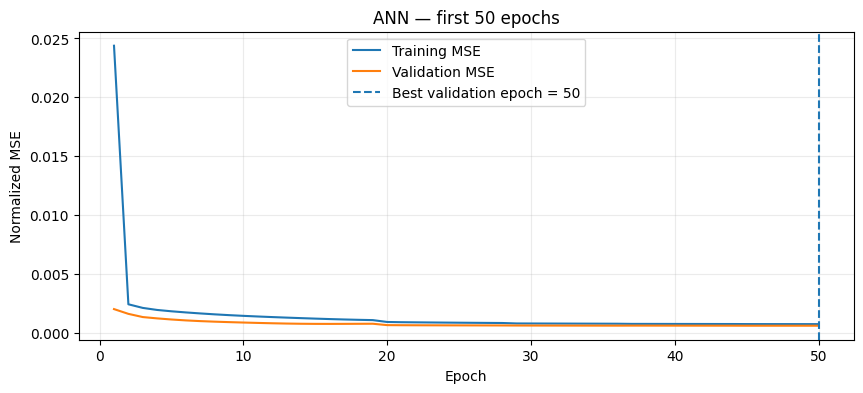

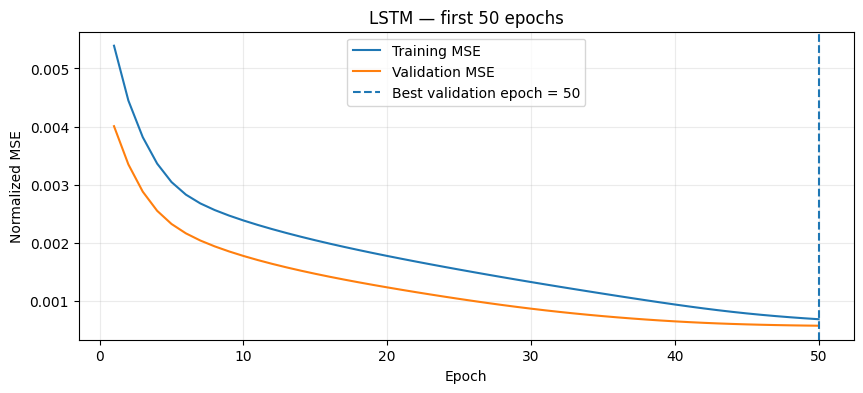

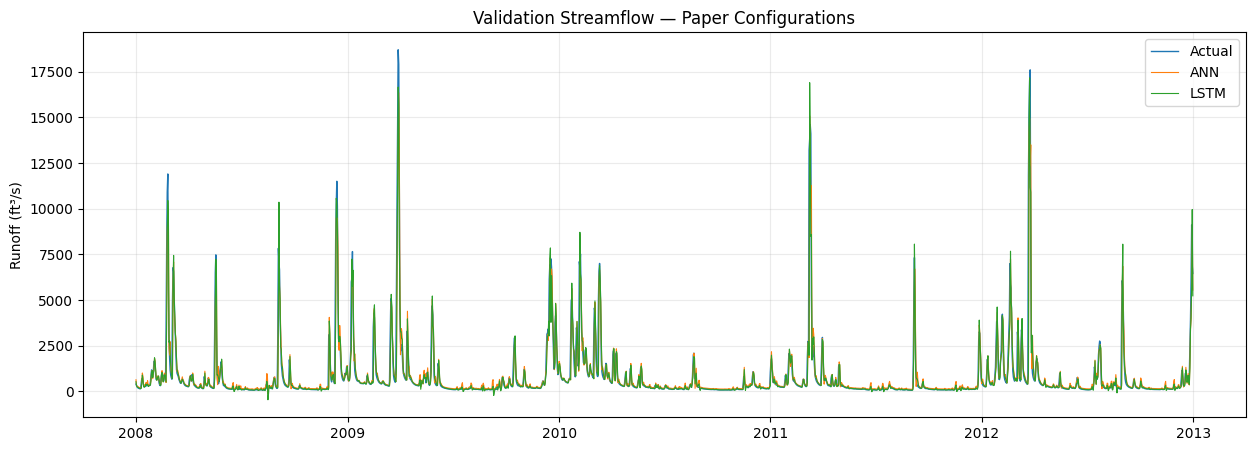

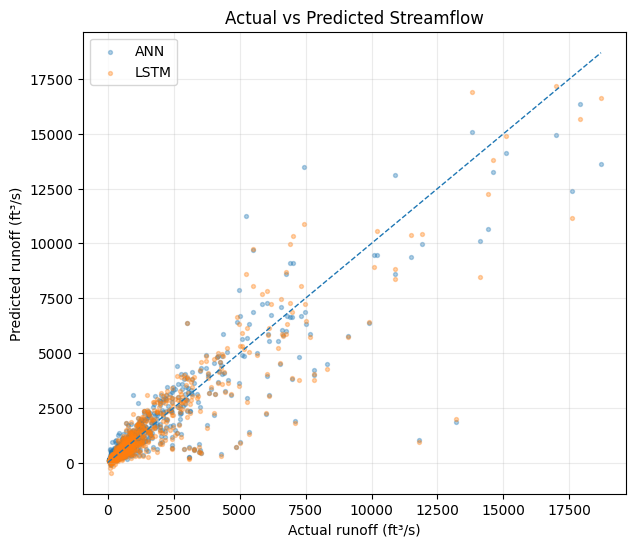

Paper vs our public-data reconstruction:


,Model,Paper Overall RMSE %,Our Overall RMSE %,Our Peak RMSE %,Our Non-peak RMSE %
0,Standard ANN,0.23,2.4005,6.6230,0.6384
1,LSTM,2.43,2.3625,6.5523,0.5765


In [8]:
# ---------- Final diagnostics, curves and paper comparison ----------

def plot_history(hist, title):
    # Zoomed view makes early convergence/overfitting visible.
    n = len(hist.history["loss"])
    zoom = min(n, 50)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(range(1, zoom+1), hist.history["loss"][:zoom], label="Training MSE")
    ax.plot(range(1, zoom+1), hist.history["val_loss"][:zoom], label="Validation MSE")
    best = int(np.argmin(hist.history["val_loss"][:zoom])) + 1
    ax.axvline(best, linestyle="--", label=f"Best validation epoch = {best}")
    ax.set_title(title + " — first 50 epochs")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Normalized MSE")
    ax.legend(); ax.grid(alpha=.25)
    plt.show()

plot_history(ann_p_hist, "ANN")
plot_history(lstm_p_hist, "LSTM")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(ann_p_va.date, ann_p_va.runoff_cfs, label="Actual", linewidth=1.0)
ax.plot(ann_p_va.date, ann_p_pred, label="ANN", linewidth=.8)
ax.plot(lstm_p_dates, lstm_p_pred, label="LSTM", linewidth=.8)
ax.set_title("Validation Streamflow — Paper Configurations")
ax.set_ylabel("Runoff (ft³/s)")
ax.legend(); ax.grid(alpha=.25)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(ann_p_va.runoff_cfs, ann_p_pred, s=8, alpha=.35, label="ANN")
ax.scatter(lstm_p_raw, lstm_p_pred, s=8, alpha=.35, label="LSTM")
mx = max(ann_p_va.runoff_cfs.max(), ann_p_pred.max(), lstm_p_raw.max(), lstm_p_pred.max())
ax.plot([0, mx], [0, mx], "--", linewidth=1)
ax.set_xlabel("Actual runoff (ft³/s)")
ax.set_ylabel("Predicted runoff (ft³/s)")
ax.set_title("Actual vs Predicted Streamflow")
ax.legend(); ax.grid(alpha=.25)
plt.show()

paper = pd.DataFrame([
    ["Standard ANN", 0.23, ann_p_metrics["RMSE_%"], ann_p_metrics["Peak_RMSE_%"], ann_p_metrics["NonPeak_RMSE_%"]],
    ["LSTM", 2.43, lstm_p_metrics["RMSE_%"], lstm_p_metrics["Peak_RMSE_%"], lstm_p_metrics["NonPeak_RMSE_%"]]
], columns=["Model","Paper Overall RMSE %","Our Overall RMSE %","Our Peak RMSE %","Our Non-peak RMSE %"])

print("Paper vs our public-data reconstruction:")
display(paper.round(4))

summary = {
    "dataset":"Public USGS + NOAA reconstruction",
    "period":"2003-2012",
    "training":"2003-2007",
    "validation":"2008-2012",
    "training_improvements":[
        "EarlyStopping with restore_best_weights=True",
        "ReduceLROnPlateau",
        "shuffle=False for time-series training"
    ],
    "paper_reported":{"ANN_RMSE_percent":0.23,"LSTM_RMSE_percent":2.43},
    "our_paper_config":{
        "ANN":ann_p_metrics,"ANN_best_epoch":ann_p_epoch,
        "LSTM":lstm_p_metrics,"LSTM_best_epoch":lstm_p_epoch
    }
}
with open("results/final_summary.json","w") as f:
    json.dump(summary, f, indent=2, default=float)

## Final interpretation

This version fixes the main weakness of the previous notebook.

### Training/model selection
The model is trained for up to **200 epochs**, but the final weights are restored from the epoch with the **lowest validation loss**. Therefore, epoch 200 is no longer automatically treated as the best model.

### Time-series handling
Training uses `shuffle=False`, preserving the temporal order of the daily observations.

### Experiments
The notebook contains:
- the paper's ANN configuration,
- the paper's LSTM configuration,
- a compact 2–7 day lag experiment,
- final 200-epoch training with best-validation-weight selection,
- RMSE, normalized RMSE, MAE, R²,
- peak and non-peak RMSE,
- training/validation curves,
- actual-vs-predicted plots,
- paper-vs-our-data comparison.

**Do not expect the exact paper's 0.23% ANN RMSE**, because our rainfall series is a public reconstruction rather than the authors' unpublished/unspecified original rainfall file. The goal here is a sound implementation of the paper's methodology on a closely related public dataset.

In [ ]:
# ================================================================
# 1. PREDICTION ON UNSEEN DATA FROM THE DATASET
# ================================================================
# The models have already been trained above. We do NOT train them again here.
#
# In this notebook, 2003-2007 is used for training and 2008-2012 is the
# held-out validation period. Therefore, these predictions are made on
# dates that were not used to fit the model weights.
#
# This cell simply takes the existing predictions and compares them with
# the actual streamflow values from the held-out part of the dataset.
# It is useful for checking how the learned ANN and LSTM perform on
# unseen real observations.

print("UNSEEN DATA PREDICTION")
print("Training period : 2003-2007")
print("Held-out period : 2008-2012")

# Actual and predicted values from the final paper-configuration models.
ann_actual = ann_p_va[["date", "runoff_cfs"]].copy()
ann_actual["ANN predicted"] = ann_p_pred

lstm_actual = pd.DataFrame({
    "date": lstm_p_dates,
    "Actual runoff": lstm_p_raw,
    "LSTM predicted": lstm_p_pred
})

display(ann_actual.head(10).round(2))
display(lstm_actual.head(10).round(2))

print("\nOverall unseen-data performance:")
display(pd.DataFrame([
    {"Model": "ANN", "RMSE (ft³/s)": ann_p_metrics["RMSE_cfs"],
     "MAE (ft³/s)": ann_p_metrics["MAE_cfs"], "R²": ann_p_metrics["R2"]},
    {"Model": "LSTM", "RMSE (ft³/s)": lstm_p_metrics["RMSE_cfs"],
     "MAE (ft³/s)": metrics(lstm_p_raw, lstm_p_pred)["MAE_cfs"],
     "R²": metrics(lstm_p_raw, lstm_p_pred)["R2"]}
]).round(4))

print("\nThe model is predicting streamflow for dataset dates it did not use during training.")


In [ ]:
# ================================================================
# 2. PREDICT STREAMFLOW FOR OUR OWN NEW SINGLE INPUT
# ================================================================
# This is a separate demonstration using the already-trained models.
# The values entered below do NOT need to come from the dataset.
#
# ANN input:
#   - rainfall from the previous 3 days
#   - streamflow from the previous 4 days
#
# LSTM input:
#   - rainfall + streamflow for the previous 5 days
#
# The trained model converts these values to the same normalized scale
# used during training, makes one prediction, and converts the result
# back to ft³/s.

def predict_custom(model="ANN"):
    model = model.upper()

    if model == "ANN":
        print("CUSTOM ANN INPUT")
        print("Enter the previous 3 rainfall values and previous 4 streamflow values.\n")
        r = [float(input(f"Rainfall {i} day(s) ago (in): ")) for i in range(1, 4)]
        q = [float(input(f"Streamflow {i} day(s) ago (ft³/s): ")) for i in range(1, 5)]

        x = np.array(r + q, dtype="float32").reshape(1, -1)
        x /= np.array([PAPER_MAX_RAINFALL]*3 + [PAPER_MAX_RUNOFF]*4, dtype="float32")
        prediction = ann_p_model.predict(x, verbose=0).ravel()[0] * PAPER_MAX_RUNOFF

    elif model == "LSTM":
        print("CUSTOM LSTM INPUT")
        print("Enter the previous 5 days from OLDEST to MOST RECENT.\n")
        rows = []
        for day in range(1, 6):
            q = float(input(f"Day {day} streamflow (ft³/s): "))
            r = float(input(f"Day {day} rainfall (in): "))
            rows.append([q / PAPER_MAX_RUNOFF, r / PAPER_MAX_RAINFALL])

        x = np.array(rows, dtype="float32").reshape(1, 5, 2)
        prediction = lstm_p_model.predict(x, verbose=0).ravel()[0] * PAPER_MAX_RUNOFF

    else:
        raise ValueError("Choose 'ANN' or 'LSTM'.")

    print(f"\nPredicted next-day streamflow ({model}): {prediction:,.2f} ft³/s")
    return prediction

# Run ONE of these after executing the cell:
# prediction = predict_custom("ANN")
# prediction = predict_custom("LSTM")

print("Custom single-input prediction is ready.")
print("Uncomment one of the two prediction lines above to enter your own values.")
